# v7 dataset analysis

Visualizes a **v7 merged rover dataset** (TX/RX joined by `spf/scripts/v7_tx_rx_merge.py`)
with the same figure vocabulary as `v5dataset_analysis.ipynb`, plus a section for the
**v7-only gain/RSSI fingerprint metadata**.

The merged files carry every v5 ground-truth key (`tx_pos/rx_pos`, `rx_theta/heading_in_pis`)
**and** the full v7 payload (`gains`, `rssis`, `gain_db_start/end`, `rssi_db_start/end`,
`iq_power_dbfs`, ...), so they load through the normal `v5spfdataset` loader (`v4=False`).

Sections:
1. TX/RX geometry (local XY track)
2. Per-receiver diagnostic panel (theta/heading, beamformer heatmap, distance, gain, RSSI)
3. Raw IQ + inter-antenna phase with segmentation overlay
4. Windowed beamformer heatmap (one session)
5. AoA: estimated theta vs ground truth
6. Angular error profile (cartesian + polar)
7. Phase-difference (phi) error analysis
8. **v7 gain/RSSI metadata** (per-buffer start/end, iq power, vs distance)

In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from spf.dataset.spf_dataset import v5spfdataset
from spf.rf import (
    pi_norm,
    torch_pi_norm,
    reduce_theta_to_positive_y,
    get_phase_diff,
    beamformer_given_steering_nomean,
    circular_diff_to_mean,
)
from spf.sdrpluto.detrend import detrend_np
from spf.dataset.segmentation import DEFAULT_SEGMENT_ARGS, simple_segment

## Load a v7 merged dataset
`PREFIX` is the merged zarr path **without** the `.zarr` extension. Swap it for any of the `rovers_july_2026/merged/*.zarr` outputs. First run builds the segmentation precompute cache (`segment_if_not_exist=True`); later runs reuse it.

In [2]:
# --- v7 merged rover datasets (July 2026, Fort Baker) ---
PREFIX = (
    "/mnt/qnap01/mouse9911/rovers_july_2026/merged/"
    "rover_2026_07_31_18_35_35_nRX2_bounce_spacing0p035_tag_RO1."
    "rover_2026_07_31_18_35_23_nRX1_circle_spacing0p05075_tag_RO2"
)
# other merged outputs (uncomment one):
# PREFIX = ".../rover_2026_07_31_18_49_02_..._tag_RO1.rover_2026_07_31_18_35_23_..._tag_RO2"
# PREFIX = ".../rover_2026_07_31_20_11_15_..._tag_RO3.rover_2026_07_31_18_35_23_..._tag_RO2"
# PREFIX = ".../rover_2026_07_31_21_18_45_..._tag_RO3.rover_2026_07_31_21_09_45_..._tag_RO2"

PRECOMPUTE_CACHE = "/mnt/qnap01/mouse9911/rovers_july_2026/precompute_cache_v7_3p5/"

ds = v5spfdataset(
    PREFIX,
    nthetas=65,
    ignore_qc=True,
    precompute_cache=PRECOMPUTE_CACHE,
    gpu=False,
    snapshots_per_session=1,
    n_parallel=8,
    paired=True,
    segment_if_not_exist=True,   # uses the current default segmentation version; builds cache on first run
)
print("dataset:", os.path.basename(ds.zarr_fn))
print("len(ds) =", len(ds), " receivers =", ds.n_receivers)

dataset: rover_2026_07_31_18_35_35_nRX2_bounce_spacing0p035_tag_RO1.rover_2026_07_31_18_35_23_nRX1_circle_spacing0p05075_tag_RO2.zarr
len(ds) = 1069  receivers = 2


## 1. TX/RX geometry
Emitter (`tx_pos`) and receiver (`rx_pos`) ground-truth positions in the local aeqd XY frame (mm). `dists` is the per-snapshot rx→tx range that later plots key off.

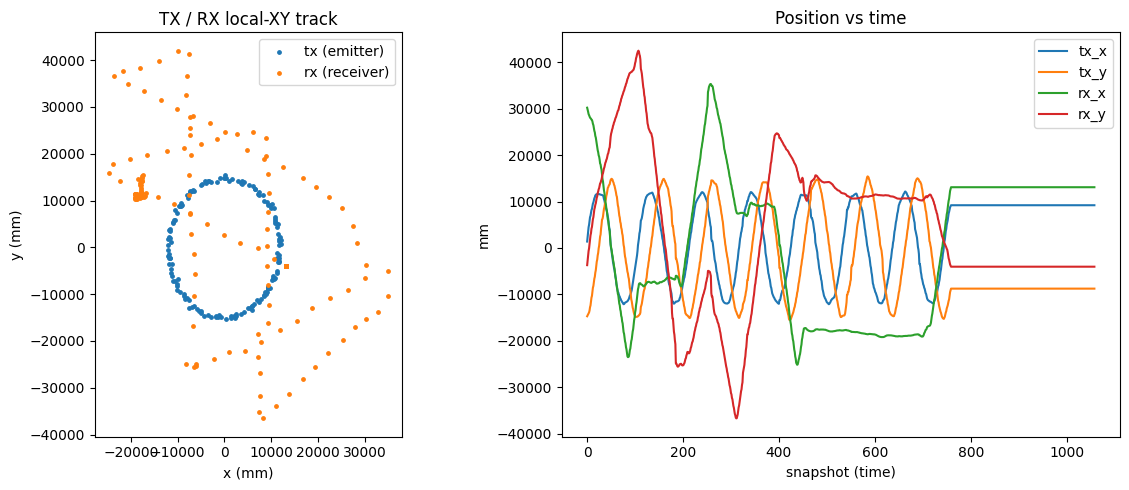

In [3]:
tx_pos = np.vstack([ds.z.receivers.r0.tx_pos_x_mm, ds.z.receivers.r0.tx_pos_y_mm])
rx_pos = np.vstack([ds.z.receivers.r0.rx_pos_x_mm, ds.z.receivers.r0.rx_pos_y_mm])
dists = np.sqrt(((rx_pos - tx_pos) ** 2).sum(axis=0)) / 1000.0  # meters

start_idx = 10
end_idx = min(6000, len(ds))
step = max(1, (end_idx - start_idx) // 200)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].scatter(tx_pos[0, start_idx:end_idx:step], tx_pos[1, start_idx:end_idx:step], s=6, label="tx (emitter)")
axs[0].scatter(rx_pos[0, start_idx:end_idx:step], rx_pos[1, start_idx:end_idx:step], s=6, label="rx (receiver)")
axs[0].set_aspect("equal"); axs[0].set_xlabel("x (mm)"); axs[0].set_ylabel("y (mm)")
axs[0].set_title("TX / RX local-XY track"); axs[0].legend()

axs[1].plot(tx_pos[0, start_idx:end_idx], label="tx_x")
axs[1].plot(tx_pos[1, start_idx:end_idx], label="tx_y")
axs[1].plot(rx_pos[0, start_idx:end_idx], label="rx_x")
axs[1].plot(rx_pos[1, start_idx:end_idx], label="rx_y")
axs[1].set_title("Position vs time"); axs[1].set_xlabel("snapshot (time)"); axs[1].set_ylabel("mm")
axs[1].legend(); fig.tight_layout()

## 2. Per-receiver diagnostic panel
For each receiver: array-relative AoA vs absolute vs rover heading; the windowed beamformer power over **angle × time**; rx→tx distance; per-element gain; per-element RSSI.

/tmp/ipykernel_2722484/140239083.py:2: RuntimeWarning: invalid value encountered in divide
  return x / x.max(axis=dim, keepdims=True)


/tmp/ipykernel_2722484/140239083.py:2: RuntimeWarning: invalid value encountered in divide
  return x / x.max(axis=dim, keepdims=True)


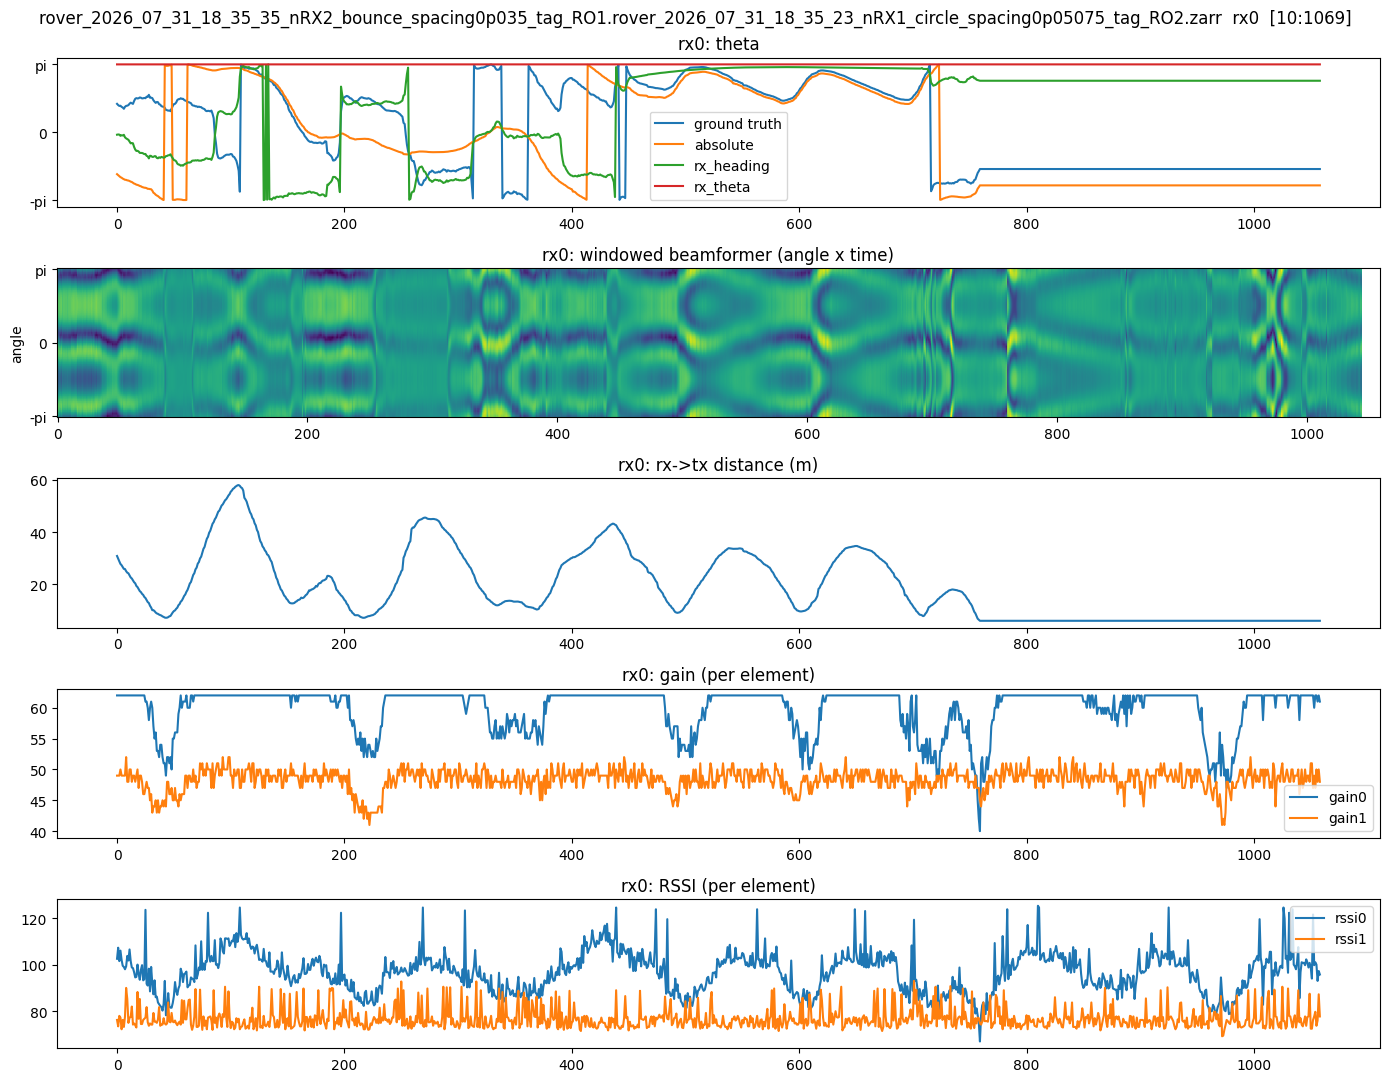

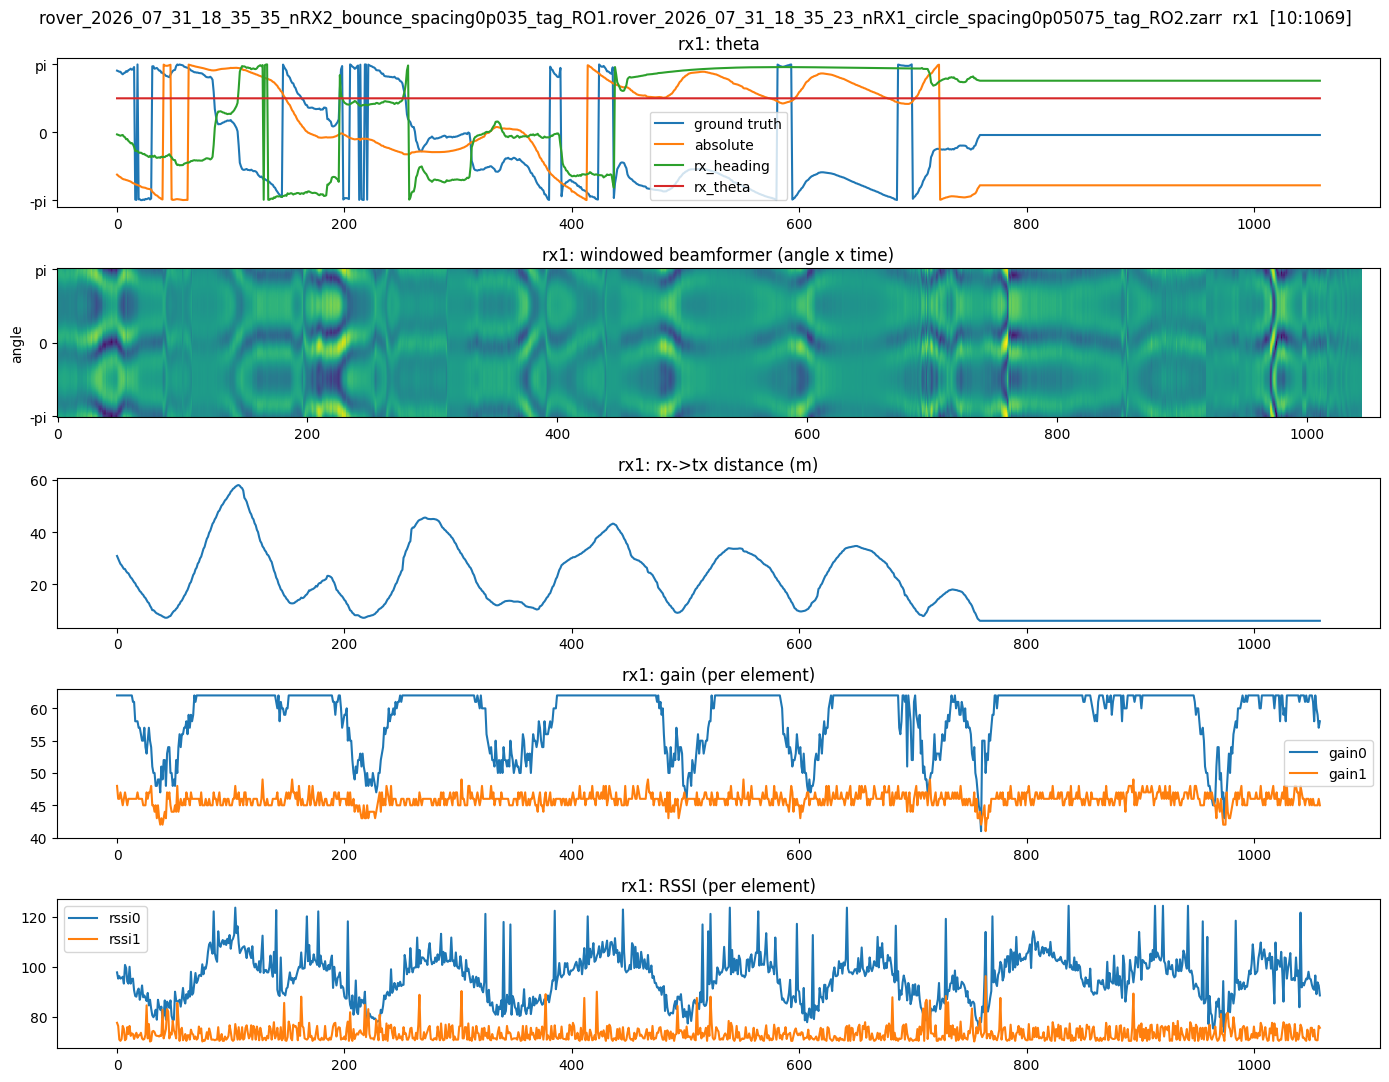

In [4]:
def normalize(x, dim):
    return x / x.max(axis=dim, keepdims=True)

for rx_idx in range(ds.n_receivers):
    fig, axs = plt.subplots(5, 1, figsize=(14, 11))
    fig.suptitle(f"{os.path.basename(ds.zarr_fn)}  rx{rx_idx}  [{start_idx}:{end_idx}]")

    axs[0].set_title(f"rx{rx_idx}: theta")
    axs[0].plot(ds.ground_truth_thetas[rx_idx][start_idx:end_idx], label="ground truth")
    axs[0].plot(ds.absolute_thetas[rx_idx][start_idx:end_idx], label="absolute")
    axs[0].plot(torch_pi_norm(ds.cached_keys[rx_idx]["rx_heading_in_pis"][start_idx:end_idx] * torch.pi), label="rx_heading")
    axs[0].plot(ds.cached_keys[rx_idx]["rx_theta_in_pis"][start_idx:end_idx] * torch.pi, label="rx_theta")
    axs[0].set_yticks([-torch.pi, 0, torch.pi]); axs[0].set_yticklabels(["-pi", "0", "pi"]); axs[0].legend()

    axs[1].set_title(f"rx{rx_idx}: windowed beamformer (angle x time)")
    x = normalize(ds.precomputed_zarr[f"r{rx_idx}"].windowed_beamformer[:].astype(np.float32), 2).mean(axis=1)[start_idx:end_idx]
    x /= x.sum(axis=1, keepdims=True)
    axs[1].imshow(x.T, origin="lower", aspect="auto")
    axs[1].set_yticks([0, 32, 64]); axs[1].set_yticklabels(["-pi", "0", "pi"]); axs[1].set_ylabel("angle")

    axs[2].set_title(f"rx{rx_idx}: rx->tx distance (m)")
    axs[2].plot(dists[start_idx:end_idx])

    axs[3].set_title(f"rx{rx_idx}: gain (per element)")
    axs[3].plot(ds.z.receivers[f"r{rx_idx}"].gains[start_idx:end_idx, 0], label="gain0")
    axs[3].plot(ds.z.receivers[f"r{rx_idx}"].gains[start_idx:end_idx, 1], label="gain1"); axs[3].legend()

    axs[4].set_title(f"rx{rx_idx}: RSSI (per element)")
    axs[4].plot(ds.z.receivers[f"r{rx_idx}"].rssis[start_idx:end_idx, 0], label="rssi0")
    axs[4].plot(ds.z.receivers[f"r{rx_idx}"].rssis[start_idx:end_idx, 1], label="rssi1"); axs[4].legend()
    fig.tight_layout()

## 3. Raw IQ + inter-antenna phase with segmentation
One snapshot's detrended IQ for both antennas, the per-sample inter-antenna phase difference, and the `simple_segment` windows overlaid (**red = signal, orange = noise**).

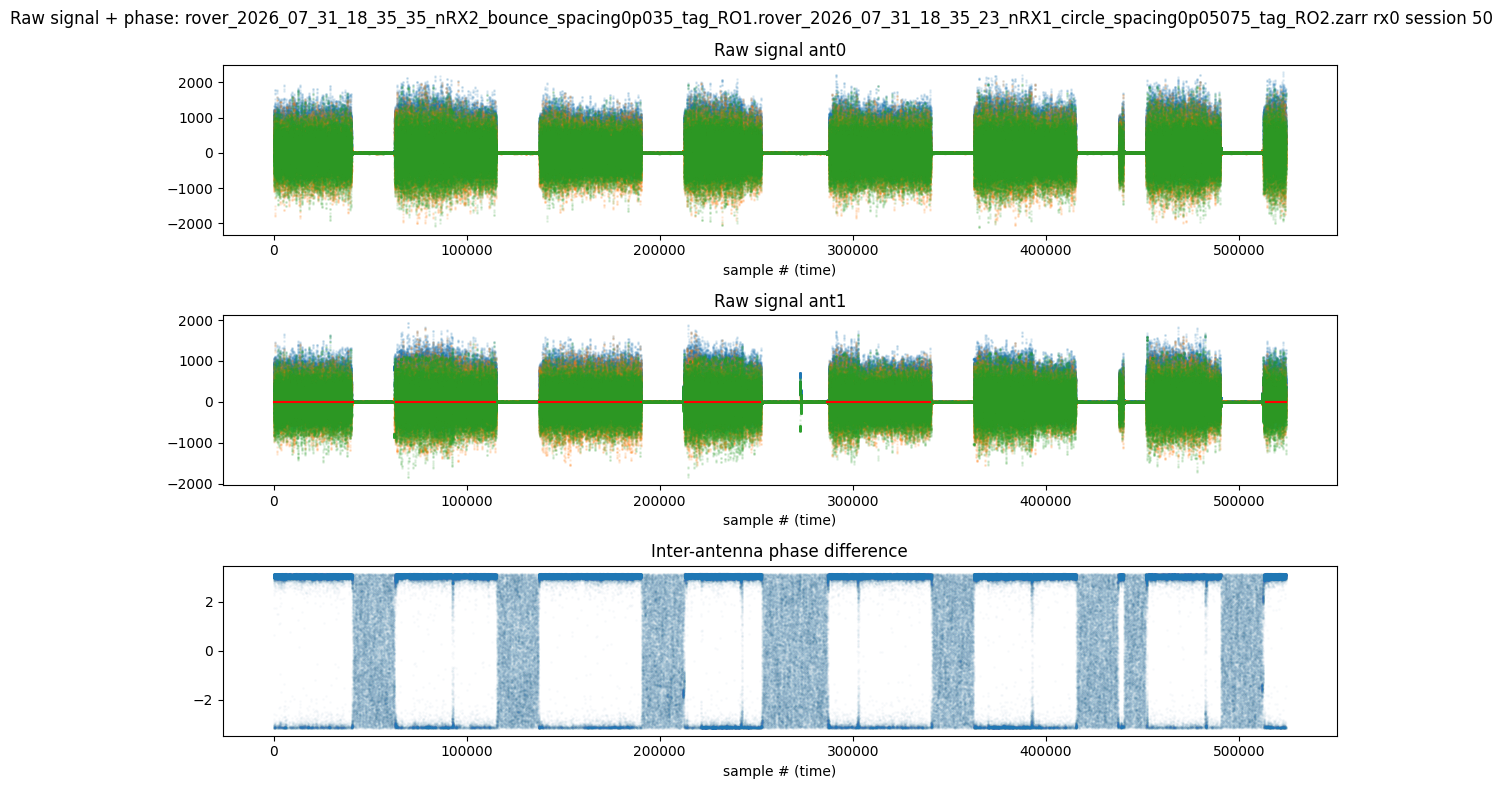

In [5]:
rx_idx = 0
session_idx = min(50, len(ds) - 1)
data = ds[session_idx][rx_idx]
n = data["signal_matrix"].shape[3]
raw = detrend_np(data["signal_matrix"][0, 0, :, :n].numpy())
phase_difference = get_phase_diff(raw)

fig, axs = plt.subplots(3, 1, figsize=(12, 8))
fig.suptitle(f"Raw signal + phase: {os.path.basename(ds.zarr_fn)} rx{rx_idx} session {session_idx}")
for a, ant in [(0, 0), (1, 1)]:
    axs[a].scatter(np.arange(n), np.abs(raw[ant]), alpha=0.1, s=1, label="|iq|")
    axs[a].scatter(np.arange(n), raw[ant].real, alpha=0.1, s=1, label="real")
    axs[a].scatter(np.arange(n), raw[ant].imag, alpha=0.1, s=1, label="imag")
    axs[a].set_title(f"Raw signal ant{ant}"); axs[a].set_xlabel("sample # (time)")
axs[2].set_title("Inter-antenna phase difference"); axs[2].set_xlabel("sample # (time)")
axs[2].scatter(np.arange(n), phase_difference, s=1, alpha=0.02)

for window in simple_segment(raw, **DEFAULT_SEGMENT_ARGS)["simple_segmentation"]:
    color = "red" if window["type"] == "signal" else "orange"
    axs[1].plot([window["start_idx"], window["end_idx"]], [window["mean"], window["mean"]], color=color)
fig.tight_layout()

## 4. Windowed beamformer heatmap (one session)
Beamformer power over **angle (65 bins, -pi..pi) x window/time** for one snapshot, normalized (top) and raw (bottom).

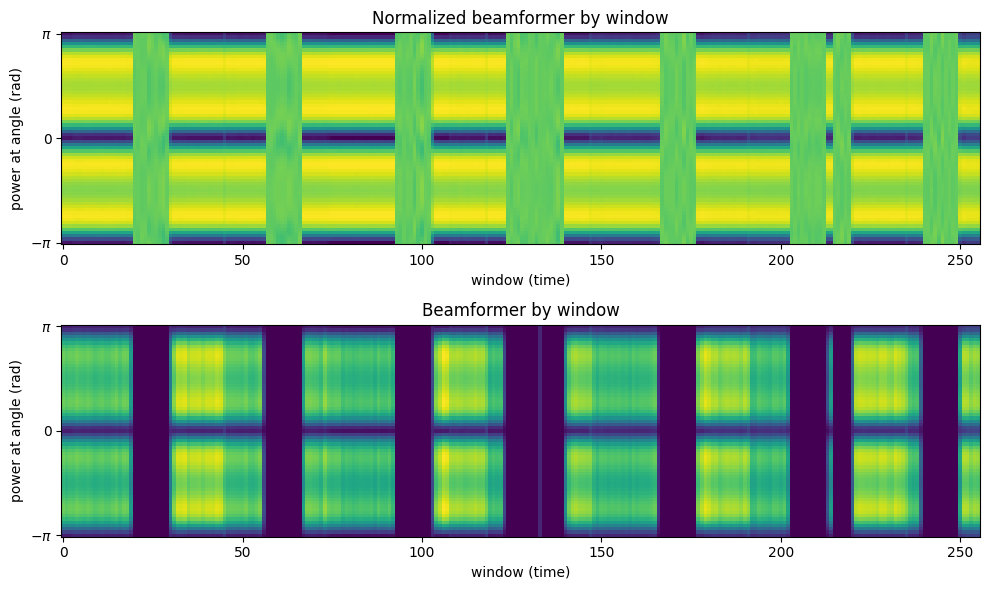

In [6]:
normed = torch.nn.functional.normalize(ds[session_idx][rx_idx]["windowed_beamformer"][0, 0, :], p=1, dim=1)
unnormed = ds[session_idx][rx_idx]["windowed_beamformer"][0, 0, :]

fig, axs = plt.subplots(2, 1, figsize=(10, 6))
axs[0].imshow(normed.T, aspect="auto", origin="lower"); axs[0].set_title("Normalized beamformer by window")
axs[1].imshow(unnormed.T, aspect="auto", origin="lower"); axs[1].set_title("Beamformer by window")
for a in axs:
    a.set_yticks([0, 32, 64]); a.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
    a.set_ylabel("power at angle (rad)"); a.set_xlabel("window (time)")
fig.tight_layout()

## 5. AoA: estimated theta vs ground truth
Top: segmented mean phase-difference vs ideal (ground-truth phi). Bottom: the two beamformer theta peaks vs ground-truth theta (and its front/back-folded form).

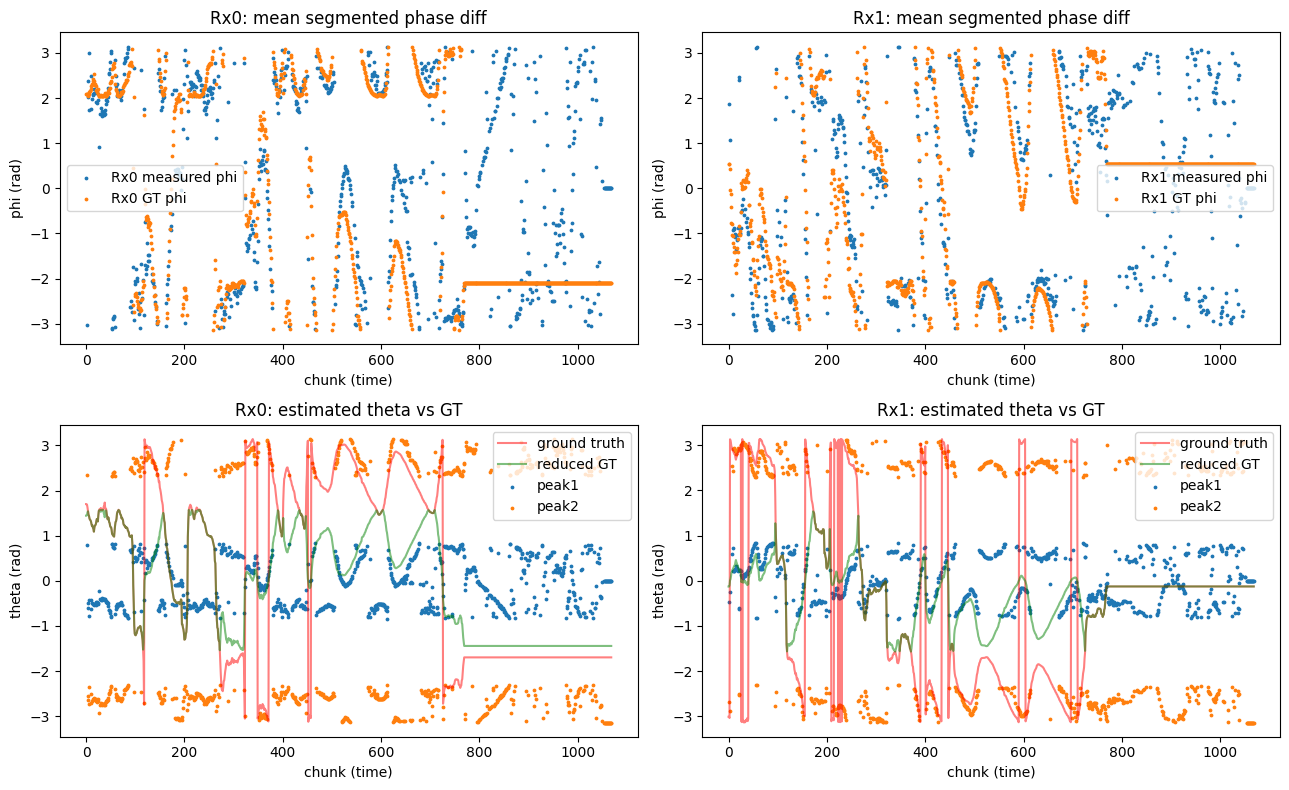

In [7]:
first_n = min(1500, len(ds))
fig, axs = plt.subplots(2, 2, figsize=(13, 8))

for rx in [0, 1]:
    axs[0, rx].scatter(range(first_n), ds.mean_phase[f"r{rx}"][:first_n], s=3, label=f"Rx{rx} measured phi")
    axs[0, rx].scatter(range(first_n), ds.ground_truth_phis[rx][:first_n], s=3, label=f"Rx{rx} GT phi")
    axs[0, rx].set_title(f"Rx{rx}: mean segmented phase diff"); axs[0, rx].set_xlabel("chunk (time)")
    axs[0, rx].set_ylabel("phi (rad)"); axs[0, rx].legend()

est = ds.get_estimated_thetas()
for rx in [0, 1]:
    gt = ds.ground_truth_thetas[rx][:first_n]
    axs[1, rx].plot(gt, alpha=0.5, color="red", label="ground truth")
    axs[1, rx].plot(reduce_theta_to_positive_y(gt), alpha=0.5, color="green", label="reduced GT")
    axs[1, rx].scatter(range(first_n), pi_norm(est[f"r{rx}"][0])[:first_n], s=3, label="peak1")
    axs[1, rx].scatter(range(first_n), pi_norm(est[f"r{rx}"][1])[:first_n], s=3, label="peak2")
    axs[1, rx].set_title(f"Rx{rx}: estimated theta vs GT"); axs[1, rx].set_xlabel("chunk (time)")
    axs[1, rx].set_ylabel("theta (rad)"); axs[1, rx].legend()
fig.tight_layout()

## 6. Angular error profile
Estimation error (min over the two AoA peaks) binned by true direction: mean +/- std in cartesian, and mean error as a polar radius.

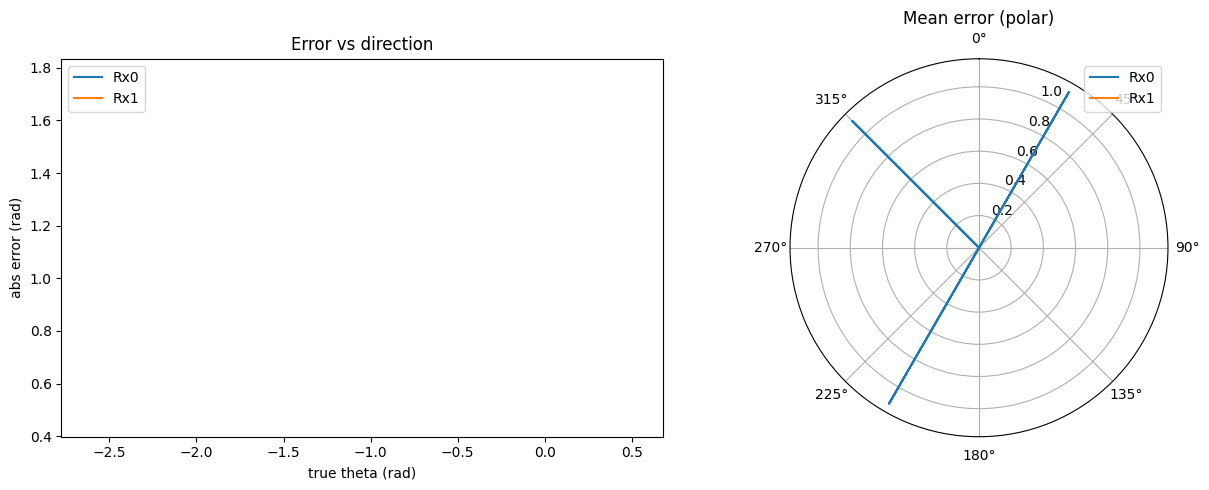

In [8]:
angle_resolution = 24
est = ds.get_estimated_thetas()

def theta_to_bin(theta, R):
    return np.rint(((pi_norm(np.asarray(theta)) / np.pi + 1) / 2) * R).astype(int)

def bin_to_theta(b, R):
    return ((b / R) * 2 - 1) * np.pi

fig = plt.figure(figsize=(13, 5))
ax0 = fig.add_subplot(1, 2, 1)
ax1 = fig.add_subplot(1, 2, 2, projection="polar")
xb = bin_to_theta(np.arange(angle_resolution), angle_resolution)

for rx in [0, 1]:
    expected = np.asarray(ds.ground_truth_thetas[rx])
    e0 = np.asarray(est[f"r{rx}"][0]); e1 = np.asarray(est[f"r{rx}"][1])
    m = min(len(expected), len(e0), len(e1))
    expected, e0, e1 = expected[:m], e0[:m], e1[:m]
    err = np.abs(np.min([circular_diff_to_mean(expected, e0), circular_diff_to_mean(expected, e1)], axis=0))
    bins = theta_to_bin(expected, angle_resolution) % angle_resolution
    means = np.array([err[bins == b].mean() if (bins == b).any() else np.nan for b in range(angle_resolution)])
    stds = np.array([err[bins == b].std() if (bins == b).any() else 0.0 for b in range(angle_resolution)])
    ax0.plot(xb, means, label=f"Rx{rx}")
    ax0.fill_between(xb, means - stds, means + stds, alpha=0.2)
    ax1.plot(xb, np.nan_to_num(means), label=f"Rx{rx}")

ax0.set_xlabel("true theta (rad)"); ax0.set_ylabel("abs error (rad)"); ax0.set_title("Error vs direction"); ax0.legend()
ax1.set_title("Mean error (polar)"); ax1.set_theta_zero_location("N"); ax1.set_theta_direction(-1); ax1.legend()
fig.tight_layout()

## 7. Phase-difference (phi) error analysis
How the measured-vs-ideal phase-difference error relates to rx->tx distance and tx position, plus its distribution.

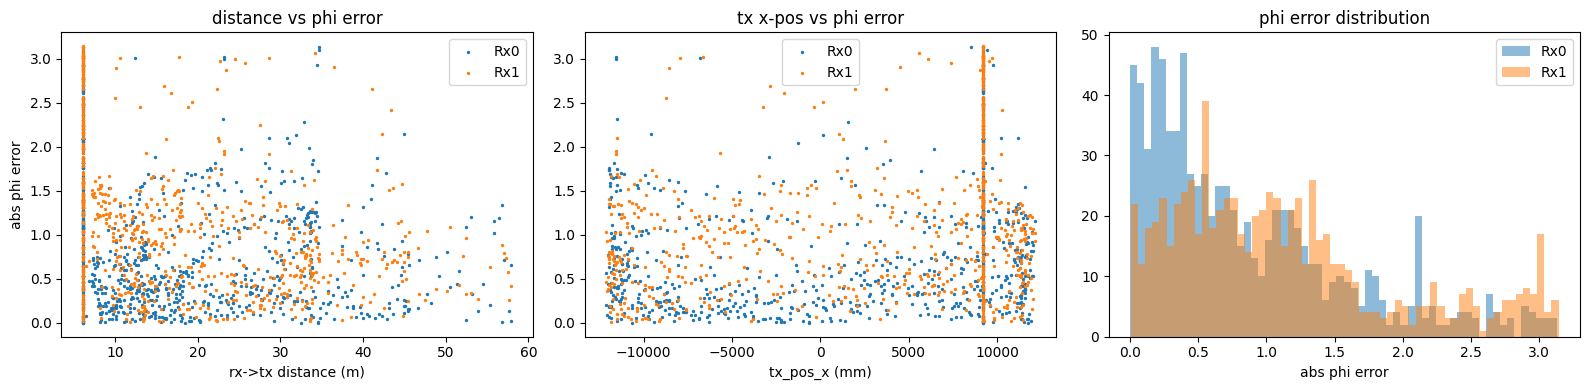

In [9]:
r_err = {rx: torch_pi_norm(ds.mean_phase[f"r{rx}"] - ds.ground_truth_phis[rx]).abs() for rx in [0, 1]}
dist_t = (ds.cached_keys[0]["tx_pos_mm"] / 1000 - ds.cached_keys[0]["rx_pos_mm"] / 1000).pow(2).sum(axis=1).sqrt()
tx_x = ds.cached_keys[0]["tx_pos_mm"][:, 0]

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for rx in [0, 1]:
    axs[0].scatter(dist_t, r_err[rx], s=2, label=f"Rx{rx}")
    axs[1].scatter(tx_x, r_err[rx], s=2, label=f"Rx{rx}")
    axs[2].hist(r_err[rx].numpy(), bins=60, alpha=0.5, label=f"Rx{rx}")
axs[0].set_title("distance vs phi error"); axs[0].set_xlabel("rx->tx distance (m)"); axs[0].set_ylabel("abs phi error"); axs[0].legend()
axs[1].set_title("tx x-pos vs phi error"); axs[1].set_xlabel("tx_pos_x (mm)"); axs[1].legend()
axs[2].set_title("phi error distribution"); axs[2].set_xlabel("abs phi error"); axs[2].legend()
fig.tight_layout()

## 8. v7 gain/RSSI fingerprint metadata (v7-only)
The direct-USB v7 capture records, **per buffer and per antenna element**, the AGC gain and RSSI at the **start and end** of the buffer, plus IQ power. `gains`/`rssis` are the end-of-buffer values; these keys are dropped by a plain v4->v5 merge but preserved here.

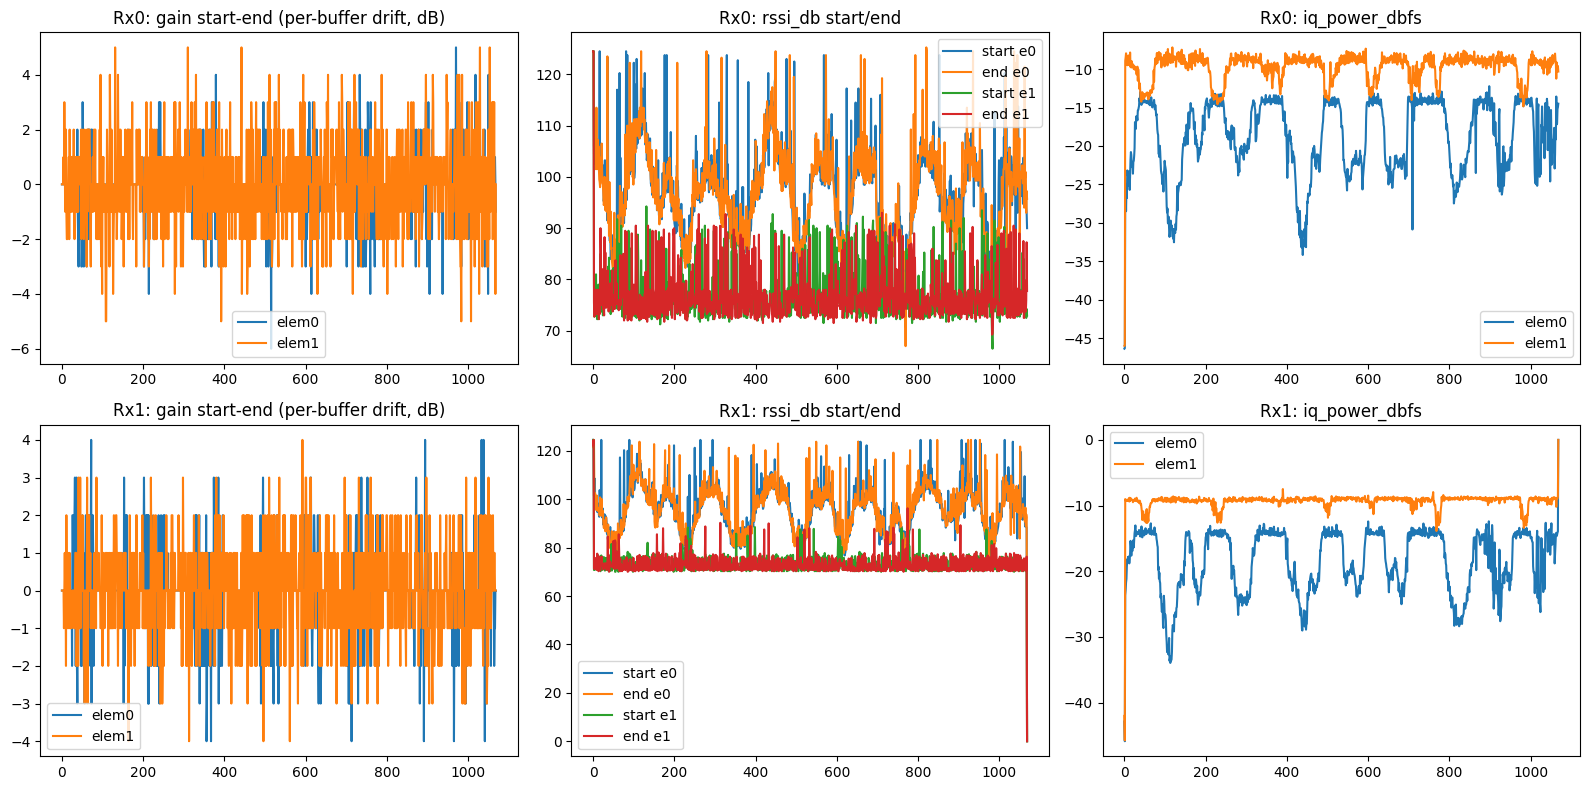

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for rx in [0, 1]:
    r = ds.z.receivers[f"r{rx}"]
    gs, ge = r["gain_db_start"][:], r["gain_db_end"][:]
    rs, re_ = r["rssi_db_start"][:], r["rssi_db_end"][:]
    iqp = r["iq_power_dbfs"][:]
    axs[rx, 0].plot(gs[:, 0] - ge[:, 0], label="elem0"); axs[rx, 0].plot(gs[:, 1] - ge[:, 1], label="elem1")
    axs[rx, 0].set_title(f"Rx{rx}: gain start-end (per-buffer drift, dB)"); axs[rx, 0].legend()
    axs[rx, 1].plot(rs[:, 0], label="start e0"); axs[rx, 1].plot(re_[:, 0], label="end e0")
    axs[rx, 1].plot(rs[:, 1], label="start e1"); axs[rx, 1].plot(re_[:, 1], label="end e1")
    axs[rx, 1].set_title(f"Rx{rx}: rssi_db start/end"); axs[rx, 1].legend()
    axs[rx, 2].plot(iqp[:, 0], label="elem0"); axs[rx, 2].plot(iqp[:, 1], label="elem1")
    axs[rx, 2].set_title(f"Rx{rx}: iq_power_dbfs"); axs[rx, 2].legend()
fig.tight_layout()

Rx0: gain_metadata_valid=1.000  rssi_metadata_valid=1.000
Rx1: gain_metadata_valid=1.000  rssi_metadata_valid=0.999


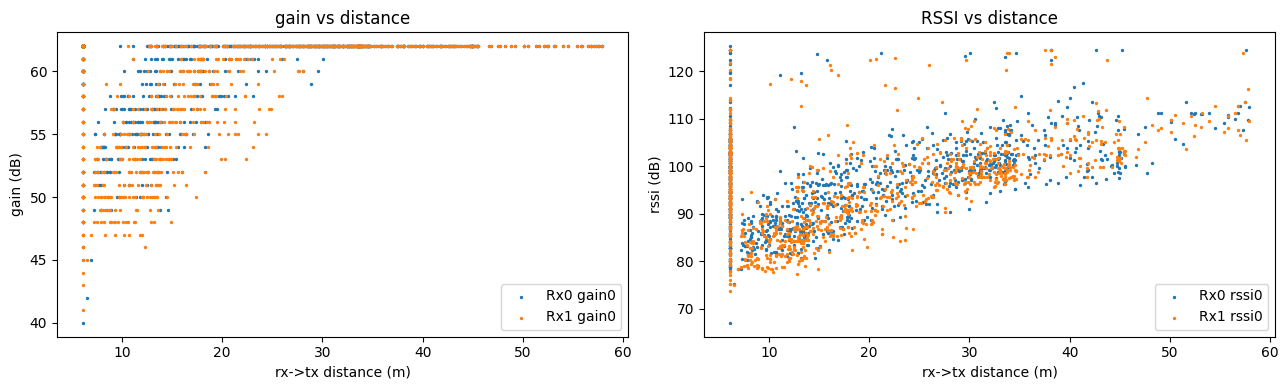

In [11]:
# gain / RSSI vs rx->tx distance, and metadata-valid coverage
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for rx in [0, 1]:
    r = ds.z.receivers[f"r{rx}"]
    axs[0].scatter(dists, r["gains"][:, 0], s=2, label=f"Rx{rx} gain0")
    axs[1].scatter(dists, r["rssis"][:, 0], s=2, label=f"Rx{rx} rssi0")
    gv = r["gain_metadata_valid"][:].mean() if "gain_metadata_valid" in r else float("nan")
    rv = r["rssi_metadata_valid"][:].mean() if "rssi_metadata_valid" in r else float("nan")
    print(f"Rx{rx}: gain_metadata_valid={gv:.3f}  rssi_metadata_valid={rv:.3f}")
axs[0].set_title("gain vs distance"); axs[0].set_xlabel("rx->tx distance (m)"); axs[0].set_ylabel("gain (dB)"); axs[0].legend()
axs[1].set_title("RSSI vs distance"); axs[1].set_xlabel("rx->tx distance (m)"); axs[1].set_ylabel("rssi (dB)"); axs[1].legend()
fig.tight_layout()